# Shariah-Compliant Portfolio Optimiser (all SPUS holdings)
Goal: build long-only, Shariah-compliant portfolios from all SPUS holdings and test them against SPUS.

Data: Yahoo Finance daily prices, 2020 to today (SPUS launched Dec 2019).

In [5]:
!pip install yfinance
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.optimize import minimize

## Step 1: Load SPUS holdings
The full holdings list is read directly from the SP Funds website (sp-funds.com), so it is always current.

In [6]:
holdings = pd.read_csv("TidalFG_Holdings_SPUS.csv")
print(holdings.columns.tolist())
holdings.head()

['Date', 'Account', 'StockTicker', 'CUSIP', 'SecurityName', 'Shares', 'Price', 'MarketValue', 'Weightings', 'NetAssets', 'SharesOutstanding', 'CreationUnits']


,Date,Account,StockTicker,CUSIP,SecurityName,Shares,Price,MarketValue,Weightings,NetAssets,SharesOutstanding,CreationUnits
0,11/19/2026,SPUS,AAPL,037833100,Apple Inc,1315554,352.45,4.636670e+08,14.16%,3.273557e+09,59250000,2370.0
1,11/19/2026,SPUS,MSFT,594918104,Microsoft Corp,669319,507.31,3.395522e+08,10.37%,3.273557e+09,59250000,2370.0
2,11/19/2026,SPUS,NVDA,67066G104,NVIDIA Corp,2181425,150.96,3.293079e+08,10.06%,3.273557e+09,59250000,2370.0
3,11/19/2026,SPUS,AVGO,11135F101,Broadcom Inc,429451,354.05,1.520471e+08,4.64%,3.273557e+09,59250000,2370.0
4,11/19/2026,SPUS,GOOGL,02079K305,Alphabet Inc,527709,282.44,1.490461e+08,4.55%,3.273557e+09,59250000,2370.0


In [7]:
# Finds the ticker and weight columns automatically
ticker_col = [c for c in holdings.columns if "ticker" in c.lower() or "symbol" in c.lower()][0]
weight_col = [c for c in holdings.columns if "weight" in c.lower()][0]

h = holdings[[ticker_col, weight_col]].copy()
h[weight_col] = pd.to_numeric(h[weight_col].astype(str).str.replace("%", ""), errors="coerce")
h[ticker_col] = h[ticker_col].astype(str).str.strip()
h = h[h[ticker_col].str.match(r"^[A-Z]+([.\-][A-Z])?$")]   # drops cash and other non-stock rows

h = h[h[weight_col] > 0]   # drops zero-value leftovers
top = h.dropna().sort_values(weight_col, ascending=False)
stocks = top[ticker_col].str.replace(".", "-", regex=False).tolist()
print(len(stocks), "tickers:", stocks[:10], "...")

215 tickers: ['AAPL', 'MSFT', 'NVDA', 'AVGO', 'GOOGL', 'LLY', 'TSLA', 'AMD', 'MU', 'XOM'] ...


## Step 2: Download prices and clean
Stocks missing more than 5% of days since 2020 (e.g. newer listings) are dropped.

In [8]:
benchmark = "SPUS"
prices = yf.download(stocks + [benchmark], start="2020-01-01")["Close"]

before = len(stocks)
prices = prices.dropna(axis=1, thresh=int(len(prices) * 0.95))
stocks = [s for s in stocks if s in prices.columns]
n = len(stocks)
print(n, "stocks kept,", before - n, "dropped")

returns = prices.ffill().pct_change().dropna()
returns.shape

/tmp/ipykernel_481/3837667297.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(stocks + [benchmark], start="2020-01-01")["Close"]
[*********************100%***********************]  216 of 216 completed


206 stocks kept, 9 dropped


(1677, 207)

## Milestone 1: Stock statistics

In [9]:
growth = (1 + returns).cumprod()
drawdown = growth / growth.cummax() - 1

summary = pd.DataFrame({
    "return": returns.mean() * 252,
    "volatility": returns.std() * 252**0.5,
    "max_drawdown": drawdown.min()
})
summary["sharpe"] = summary["return"] / summary["volatility"]
summary.sort_values("sharpe", ascending=False).round(2).head(15)

,return,volatility,max_drawdown,sharpe
Ticker,,,,
PWR,0.54,0.39,-0.35,1.40
FIX,0.65,0.48,-0.53,1.35
MCK,0.36,0.27,-0.27,1.34
AVGO,0.55,0.43,-0.41,1.28
LLY,0.41,0.33,-0.34,1.24
NVDA,0.62,0.50,-0.66,1.24
CAH,0.34,0.27,-0.25,1.23
GWW,0.32,0.26,-0.25,1.21
STLD,0.47,0.40,-0.32,1.17


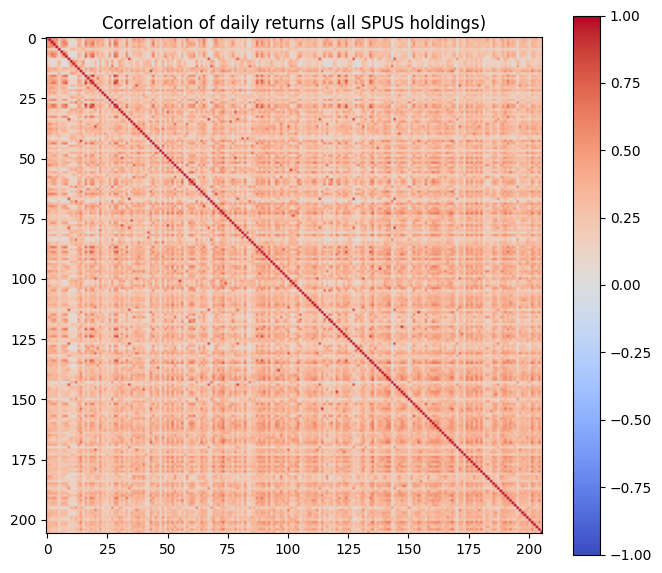

Average correlation: 0.3


In [10]:
corr = returns[stocks].corr()
plt.figure(figsize=(8,7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.title("Correlation of daily returns (all SPUS holdings)")
plt.savefig("heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Average correlation:", round(corr.values[np.triu_indices(n, 1)].mean(), 2))

## Milestone 2: Random portfolios
With 200+ stocks, random weights average out, so the cloud is much tighter than in v1.

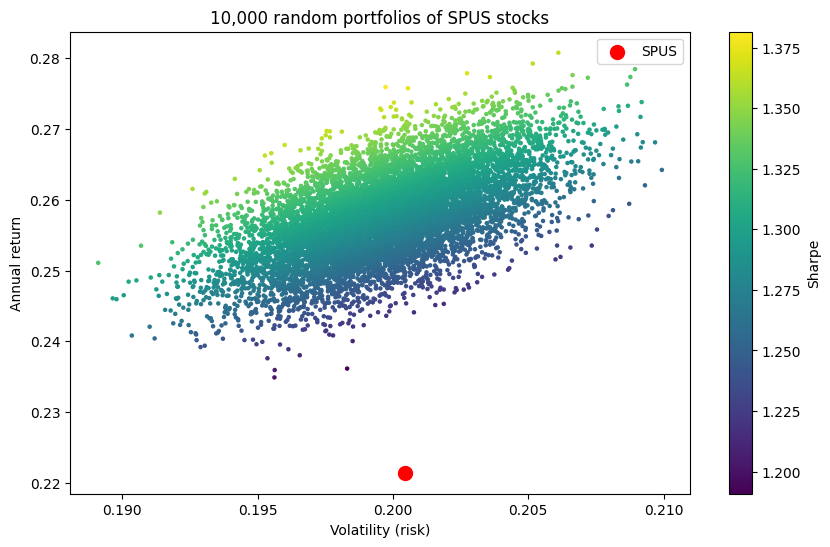

In [11]:
mean_returns = returns[stocks].mean() * 252
cov_matrix = returns[stocks].cov() * 252

def port_stats(w, mu=mean_returns, cov=cov_matrix):
    r = np.dot(w, mu)
    v = np.sqrt(w @ cov @ w)
    return r, v, r / v

np.random.seed(42)
results = []
for i in range(10000):
    w = np.random.random(n)
    w = w / w.sum()
    results.append(list(port_stats(w)))

portfolios = pd.DataFrame(results, columns=["return", "volatility", "sharpe"])

spus_r = returns[benchmark].mean() * 252
spus_v = returns[benchmark].std() * 252**0.5

plt.figure(figsize=(10,6))
plt.scatter(portfolios["volatility"], portfolios["return"], c=portfolios["sharpe"], cmap="viridis", s=5)
plt.colorbar(label="Sharpe")
plt.scatter(spus_v, spus_r, color="red", s=100, label="SPUS")
plt.xlabel("Volatility (risk)")
plt.ylabel("Annual return")
plt.title("10,000 random portfolios of SPUS stocks")
plt.legend()
plt.show()

## Milestone 3: Optimal portfolios (full period)
Long-only, weights sum to 100%, max 2% per stock.

In [12]:
constraints = {"type": "eq", "fun": lambda w: w.sum() - 1}
start = np.array([1/n] * n)

def optimise(data, objective, max_weight=0.02):
    mu = data[stocks].mean() * 252
    cov = data[stocks].cov() * 252
    if objective == "sharpe":
        fun = lambda w: -port_stats(w, mu, cov)[2]
    else:
        fun = lambda w: port_stats(w, mu, cov)[1]
    result = minimize(fun, start, method="SLSQP",
                      bounds=[(0, max_weight)] * n, constraints=constraints)
    return result.x

w_sharpe_full = optimise(returns, "sharpe")
w_minvol_full = optimise(returns, "minvol")

weights_full = pd.DataFrame({"max_sharpe": w_sharpe_full, "min_vol": w_minvol_full}, index=stocks)
print("Stocks held (>0.5%):", (weights_full["max_sharpe"] > 0.005).sum(), "max Sharpe,",
      (weights_full["min_vol"] > 0.005).sum(), "min vol")
weights_full.sort_values("max_sharpe", ascending=False).round(3).head(20)

Stocks held (>0.5%): 54 max Sharpe, 56 min vol


,max_sharpe,min_vol
VRT,0.02,0.000
MU,0.02,0.000
FANG,0.02,0.000
FIX,0.02,0.000
EOG,0.02,0.015
ANET,0.02,0.000
NVDA,0.02,0.000
COP,0.02,0.000
STLD,0.02,0.000
STX,0.02,0.012


## Milestone 4: Out-of-sample backtest
Weights are optimised on 2020-2023 only and tested on 2024 to today.

In [13]:
train = returns.loc[:"2023"]
test = returns.loc["2024":]

w_sharpe = optimise(train, "sharpe")
w_minvol = optimise(train, "minvol")
w_equal = start

port_test = pd.DataFrame({
    "max_sharpe": test[stocks] @ w_sharpe,
    "min_vol": test[stocks] @ w_minvol,
    "equal": test[stocks] @ w_equal,
    "SPUS": test[benchmark]
})

def perf(r):
    g = (1 + r).cumprod()
    dd = (g / g.cummax() - 1).min()
    ann_r = r.mean() * 252
    ann_v = r.std() * 252**0.5
    return pd.Series({"return": ann_r, "volatility": ann_v,
                      "sharpe": ann_r / ann_v, "max_drawdown": dd})

results_test = port_test.apply(perf).round(3)
results_test

,max_sharpe,min_vol,equal,SPUS
return,0.213,0.164,0.185,0.191
volatility,0.156,0.116,0.166,0.185
sharpe,1.368,1.405,1.112,1.029
max_drawdown,-0.197,-0.106,-0.211,-0.228


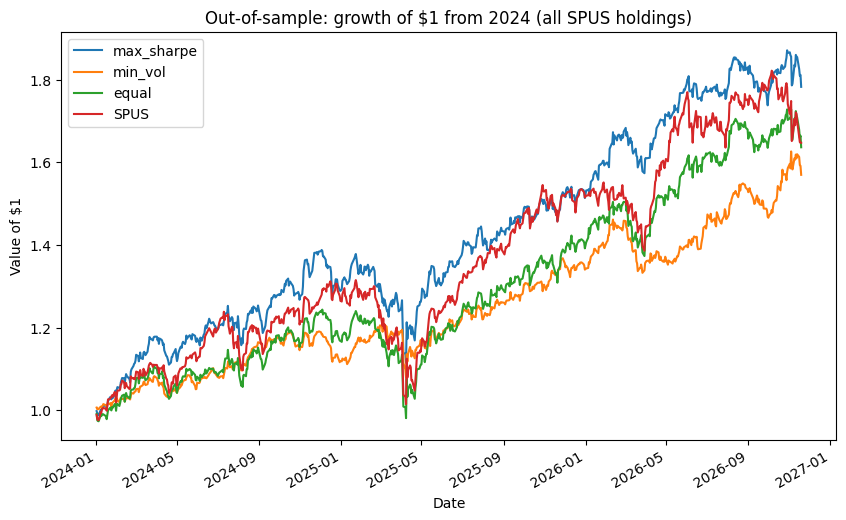

In [14]:
(1 + port_test).cumprod().plot(figsize=(10,6), title="Out-of-sample: growth of $1 from 2024 (all SPUS holdings)")
plt.ylabel("Value of $1")
plt.savefig("backtest.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
amount = 10000          # how much to invest, in USD
strategy = "minvol"     # "minvol" or "sharpe"
lookback_years = 3      # how much recent history to use
max_weight = 0.10       # max 10% per stock
min_weight = 0.01       # drop positions under 1%

# 1. Optimise on recent data
recent = returns.loc[returns.index[-1] - pd.DateOffset(years=lookback_years):]
w = pd.Series(optimise(recent, strategy, max_weight=max_weight), index=stocks)

# 2. Drop tiny positions, rescale to 100%, and keep every stock under the cap
w = w[w >= min_weight]
w = w / w.sum()
for _ in range(100):
    over = w > max_weight + 1e-9
    if not over.any():
        break
    excess = (w[over] - max_weight).sum()
    w[over] = max_weight
    w[~over] += excess * w[~over] / w[~over].sum()

# 3. Buy whole shares, then spend the leftover cash
price = prices[w.index].iloc[-1]
target = w * amount
shares = (target // price).astype(int)
cash = amount - (shares * price).sum()

while True:
    can_buy = (price <= cash) & ((shares + 1) * price <= max_weight * amount)
    if not can_buy.any():
        break
    gap = (target - shares * price)[can_buy]   # how far each stock is below its target
    pick = gap.idxmax()
    shares[pick] += 1
    cash -= price[pick]

plan = pd.DataFrame({"target_weight": w.round(3), "price": price.round(2), "shares": shares})
plan["value"] = (plan["shares"] * plan["price"]).round(0)
plan["actual_weight"] = (plan["value"] / amount).round(3)
plan = plan[plan["shares"] > 0].sort_values("value", ascending=False)

print(len(plan), "stocks | invested:", round(amount - cash), "USD | cash left:", round(cash), "USD")
print("Largest position:", plan["actual_weight"].max())
plan

23 stocks | invested: 9970 USD | cash left: 30 USD
Largest position: 0.1


,target_weight,price,shares,value,actual_weight
MSFT,0.084,498.30,2,997.0,0.100
XOM,0.100,158.93,6,954.0,0.095
PG,0.093,167.85,5,839.0,0.084
JNJ,0.100,267.14,3,801.0,0.080
COR,0.065,341.25,2,682.0,0.068
CHD,0.066,109.68,6,658.0,0.066
GOOGL,0.042,272.66,2,545.0,0.054
STX,0.016,521.39,1,521.0,0.052
RSG,0.040,246.49,2,493.0,0.049
CF,0.051,115.76,4,463.0,0.046


## Findings
1. The safest portfolio won **:** min volatility had the best Sharpe ratio (1.45), an example of the low-volatility anomaly.
2. Doing nothing clever matched the fund:** equal weight earned the same return as SPUS with less risk.
3. Apple got 0%: it moves too closely with Microsoft and NVIDIA to add any diversification.
4. Boring stocks diversified best: ExxonMobil, CF Industries and the waste companies kept appearing because they move differently from tech.
5. One sell-off did a lot of the work: much of min-vol's advantage came from holding up in April 2025.
6. Honest data shrank the edge: using all holdings instead of the top 100 cut outperformance from about 16 points a year to about 3.

## Limitations
- Stocks are today's SPUS holdings, so some survivorship bias remains.
- Weights are rebalanced daily in the backtest, with no transaction costs.
- Sharpe ratios ignore the risk-free rate.
- Covariance estimates for 200+ stocks are noisy, which is why weights are capped at 2%.